# NLP Analysis of Sepsis Discharge Summaries in MIMIC-III

## Objective

This tutorial compares spaCy, SciSpaCy, and MedSpaCy for processing
clinical discharge summaries from patients with sepsis in MIMIC-III.

For each NLP approach, the analysis demonstrates:

1. Clinical entity extraction
2. Word2Vec embeddings
3. Tuned t-SNE visualization

The results are then compared to evaluate how general-purpose,
biomedical, and clinical NLP approaches differ when applied to
medical notes.

## Dataset

A sepsis cohort was identified from MIMIC-III using ICD-9 codes:

- 038xx — septicemia
- 99591 — sepsis
- 99592 — severe sepsis
- 78552 — septic shock

The original NOTEEVENTS table was streamed locally and discharge
summaries corresponding to the selected sepsis admissions were
retained. One discharge summary was selected per hospital admission.

The final corpus contains 500 discharge summaries from 500 hospital
admissions.

In [1]:
# Install a compatible, reproducible NLP/scientific Python stack.
# SciSpaCy 0.5.5 requires NumPy < 2.0.
# Note: "Run all cells" will not work for this notebook.
# There is a restart cell below this one as well as a
# file upload cell for the output from the data preparation notebook.

%pip install -q --no-cache-dir \
    "numpy==1.26.4" \
    "pandas==2.2.2" \
    "scipy==1.12.0" \
    "scikit-learn==1.5.2" \
    "gensim==4.3.3" \
    "spacy==3.7.5" \
    "scispacy==0.5.5" \
    "medspacy==1.3.1" \
    "matplotlib" \
    "tqdm"

In [ ]:
# IMPORTANT:
# Restart the runtime after changing NumPy so compiled libraries
# load against the newly installed NumPy version.

import os
os.kill(os.getpid(), 9)

In [1]:
# The regular spaCy model
!python -m spacy download en_core_web_md

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.8/42.8 MB 20.2 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
# The SciSpaCy core model
%pip install -q \
https://s3-us-west-2.amazonaws.com/ai2-s2-scispacy/releases/v0.5.4/en_core_sci_sm-0.5.4.tar.gz

  Preparing metadata (setup.py) ... done


In [3]:
# The biomedical disease/chemical NER model
%pip install -q \
https://s3-us-west-2.amazonaws.com/ai2-s2-scispacy/releases/v0.5.4/en_ner_bc5cdr_md-0.5.4.tar.gz

  Preparing metadata (setup.py) ... done


In [4]:
import sys
import numpy as np
import pandas as pd
import scipy
import sklearn
import gensim
import spacy
import scispacy
import medspacy

print(f"Python        : {sys.version.split()[0]}")
print(f"NumPy         : {np.__version__}")
print(f"pandas        : {pd.__version__}")
print(f"SciPy         : {scipy.__version__}")
print(f"scikit-learn  : {sklearn.__version__}")
print(f"gensim        : {gensim.__version__}")
print(f"spaCy         : {spacy.__version__}")
print(f"SciSpaCy      : {scispacy.__version__}")
print(f"MedSpaCy      : {medspacy.__version__}")

Python        : 3.11.13
NumPy         : 1.26.4
pandas        : 2.2.2
SciPy         : 1.12.0
scikit-learn  : 1.5.2
gensim        : 4.3.3
spaCy         : 3.7.5
SciSpaCy      : 0.5.5
MedSpaCy      : 1.3.1


In [5]:
# Verify that the libraries can actually perform basic operations

test_df = pd.DataFrame({
    "x": np.arange(5)
})

print(test_df)

assert np.__version__ == "1.26.4"
assert pd.__version__ == "2.2.2"

print("\nEnvironment validation passed.")

   x
0  0
1  1
2  2
3  3
4  4

Environment validation passed.


In [6]:
# Run to upload sepsis_discharge_notes.csv.gz from your local machine
from google.colab import files
uploaded = files.upload()

Saving sepsis_discharge_notes.csv.gz to sepsis_discharge_notes.csv.gz


In [7]:
PATH_NOTES = next(iter(uploaded))
assert PATH_NOTES == "sepsis_discharge_notes.csv.gz"

notes = pd.read_csv(
    PATH_NOTES,
    compression="gzip"
)

print(f"Loaded: {PATH_NOTES}")
print(f"Shape: {notes.shape}")

notes.info()

Loaded: sepsis_discharge_notes.csv.gz
Shape: (500, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   SUBJECT_ID         500 non-null    int64 
 1   HADM_ID            500 non-null    int64 
 2   CHARTDATE          500 non-null    object
 3   CATEGORY           500 non-null    object
 4   DESCRIPTION        500 non-null    object
 5   TEXT               500 non-null    object
 6   TEXT_LENGTH        500 non-null    int64 
 7   SEPSIS_ICD9_CODES  500 non-null    object
dtypes: int64(3), object(5)
memory usage: 31.4+ KB


In [8]:
import re
import matplotlib.pyplot as plt

from collections import Counter
from tqdm.auto import tqdm

import spacy
import medspacy

from gensim.models import Word2Vec

from sklearn.manifold import TSNE, trustworthiness
from sklearn.preprocessing import normalize

# Make sure TEXT is usable
notes["TEXT"] = notes["TEXT"].fillna("").astype(str)

print(f"Notes:             {len(notes):,}")
print(f"Unique admissions: {notes['HADM_ID'].nunique():,}")
print(f"Unique patients:   {notes['SUBJECT_ID'].nunique():,}")
print(f"Missing TEXT:      {notes['TEXT'].isna().sum():,}")

assert len(notes) == 500
assert notes["HADM_ID"].nunique() == 500
assert notes["TEXT"].str.len().min() > 0
assert notes["TEXT"].notna().all()
assert not notes["HADM_ID"].duplicated().any()

print("\nDataset validation passed.")

Notes:             500
Unique admissions: 500
Unique patients:   492
Missing TEXT:      0

Dataset validation passed.


## NLP and Embedding Methodology

The same 500 MIMIC-III sepsis discharge summaries are analyzed using
three NLP approaches:

- **spaCy**: general-purpose English named entity recognition
- **SciSpaCy**: biomedical named entity recognition
- **MedSpaCy**: biomedical named entity recognition using the same `en_ner_bc5cdr_md` model as SciSpaCy, augmented with clinical context such as negation, uncertainty, historical status, hypothetical status, and family experiencer

For each approach:

1. Entities are extracted from all 500 discharge summaries.
2. Multi-word entities are normalized into single Word2Vec tokens
   (for example, `septic shock` becomes `septic_shock`).
3. A Word2Vec model is trained on the sequence of extracted entities
   in each note.
4. Frequently occurring entity embeddings are reduced from 100
   dimensions to 2 dimensions using t-SNE.
5. Multiple t-SNE perplexities are evaluated, and the configuration
   with the highest trustworthiness score is selected.

This common workflow allows direct comparison of the entities and
embedding structure produced by the three NLP approaches.

In [9]:
# Common helper functions
def normalize_entity_text(text):
    """
    Convert an extracted entity into one Word2Vec token.

    Example:
        'Septic shock' -> 'septic_shock'
    """
    text = str(text).strip().lower()
    # Remove intermediate whitespaces
    text = re.sub(r"\s+", " ", text)

    if not text:
        return None

    # Remove entities that are only numbers
    if re.fullmatch(r"[\d.,:/%-]+", text):
        return None

    return text.replace(" ", "_")

def extract_entities(
    nlp,
    texts,
    hadm_ids,
    model_name,
    batch_size=8
):
    """
    Run an NLP pipeline over all notes.

    Returns
    -------
    entity_df:
        One row per extracted entity.
    entity_sequences:
        One list of normalized entity tokens per note.
        These sequences are used to train Word2Vec.
    """

    rows = []
    entity_sequences = []

    docs = nlp.pipe(
        texts,
        batch_size=batch_size
    )

    for i, doc in enumerate(
        tqdm(docs, total=len(texts), desc=model_name)
    ):
        hadm_id = hadm_ids[i]
        note_entities = []

        for ent in doc.ents:

            entity_text = re.sub(
                r"\s+", " ", ent.text.strip()
            )

            token = normalize_entity_text(entity_text)

            if token is None:
                continue

            note_entities.append(token)

            rows.append({
                "MODEL": model_name,
                "HADM_ID": hadm_id,
                "ENTITY": entity_text,
                "LABEL": ent.label_,
                "TOKEN": token
            })

        entity_sequences.append(note_entities)

    entity_df = pd.DataFrame(rows)

    return entity_df, entity_sequences

def summarize_entities(entity_df, model_name, top_n=20):

    print(f"\n{model_name}")
    print("=" * len(model_name))

    print(f"Total entity mentions: "
          f"{len(entity_df):,}")

    print(f"Unique entities: "
          f"{entity_df['TOKEN'].nunique():,}")

    print(f"Admissions with entities: "
          f"{entity_df['HADM_ID'].nunique():,}")

    print("\nEntity labels:")
    display(
        entity_df["LABEL"]
        .value_counts()
        .rename_axis("LABEL")
        .reset_index(name="COUNT")
    )

    print(f"\nTop {top_n} entities:")
    display(
        entity_df["TOKEN"]
        .value_counts()
        .head(top_n)
        .rename_axis("ENTITY")
        .reset_index(name="COUNT")
    )

In [10]:
# Common Word2Vec functions
def train_entity_word2vec(
    entity_sequences,
    model_name,
    vector_size=100,
    window=5,
    min_count=2,
    epochs=50
):
    """
    Train Word2Vec using each note's extracted entities
    as a sequence of concept tokens.
    """

    usable_sequences = [
        seq for seq in entity_sequences
        if len(seq) > 0
    ]

    print(
        f"{model_name}: "
        f"{len(usable_sequences):,} notes contain entities"
    )

    total_entity_tokens = sum(
        len(seq) for seq in usable_sequences
    )

    print(
        f"{model_name}: "
        f"{total_entity_tokens:,} entity tokens "
        "available for Word2Vec"
    )

    model = Word2Vec(
        sentences=usable_sequences,
        vector_size=vector_size,
        window=window,
        min_count=min_count,
        sg=1,          # Skip-gram
        negative=10,
        epochs=epochs,
        workers=1,    # improves reproducibility
        seed=42
    )

    print(
        f"{model_name} Word2Vec vocabulary: "
        f"{len(model.wv):,} entities"
    )

    return model

def show_similar_entities(
    word2vec_model,
    query_terms,
    topn=5
):
    for term in query_terms:

        token = normalize_entity_text(term)

        print(f"\nQuery: {term}")

        if token not in word2vec_model.wv:
            print("  Not present in Word2Vec vocabulary.")
            continue

        for similar_token, similarity in \
                word2vec_model.wv.most_similar(
                    token,
                    topn=topn
                ):

            pretty = similar_token.replace("_", " ")

            print(
                f"  {pretty:<35} "
                f"{similarity:.3f}"
            )

In [11]:
# Common tuned t-SNE functions
def prepare_tsne_data(
    entity_df,
    word2vec_model,
    n_entities=50
):
    """
    Select the most frequent extracted entities
    that have trained Word2Vec vectors.
    """

    counts = entity_df["TOKEN"].value_counts()

    terms = [
        token
        for token in counts.index
        if token in word2vec_model.wv
    ][:n_entities]

    if len(terms) < 6:
        raise ValueError(
            "Too few entities available for t-SNE."
        )

    vectors = np.vstack([
        word2vec_model.wv[token]
        for token in terms
    ])

    # Normalize vectors before dimensionality reduction
    vectors = normalize(vectors)

    frequencies = [
        counts[token]
        for token in terms
    ]

    return terms, vectors, frequencies

# tune perplexity
def tune_tsne(
    vectors,
    perplexities=(5, 10, 15, 20, 30, 40),
    random_state=42
):
    """
    Run t-SNE over several perplexity values.

    Trustworthiness measures preservation of local
    neighborhoods from the original embedding space.
    """

    results = []
    embeddings = {}

    n_samples = vectors.shape[0]

    valid_perplexities = [
        p for p in perplexities
        if p < n_samples
    ]

    for perplexity in valid_perplexities:

        tsne = TSNE(
            n_components=2,
            perplexity=perplexity,
            learning_rate="auto",
            init="pca",
            max_iter=1500,
            random_state=random_state
        )

        coords = tsne.fit_transform(vectors)

        n_neighbors = min(
            5,
            max(1, (n_samples - 1) // 3)
        )

        trust = trustworthiness(
            vectors,
            coords,
            n_neighbors=n_neighbors
        )

        results.append({
            "perplexity": perplexity,
            "trustworthiness": trust,
            "KL_divergence": tsne.kl_divergence_
        })

        embeddings[perplexity] = coords

    results_df = pd.DataFrame(results)

    results_df = results_df.sort_values(
        "trustworthiness",
        ascending=False
    ).reset_index(drop=True)

    best_perplexity = int(
        results_df.iloc[0]["perplexity"]
    )

    return (
        results_df,
        best_perplexity,
        embeddings
    )

def plot_tsne(
    terms,
    coordinates,
    title
):
    plt.figure(figsize=(12, 9))

    plt.scatter(
        coordinates[:, 0],
        coordinates[:, 1],
        s=45,
        alpha=0.75
    )

    for i, term in enumerate(terms):

        label = term.replace("_", " ")

        plt.annotate(
            label,
            (
                coordinates[i, 0],
                coordinates[i, 1]
            ),
            fontsize=8,
            alpha=0.85
        )

    plt.title(title)
    plt.xlabel("t-SNE dimension 1")
    plt.ylabel("t-SNE dimension 2")
    plt.tight_layout()
    plt.show()

In [12]:
# create a short, clinically relevant excerpt from one discharge summary
# Run spaCy, SciSpaCy, and MedSpaCy on the same text
# and visually compare what each one extracts
def find_clinical_window(
    dataframe,
    search_term="sepsis",
    before=1200,
    after=1800
):
    matching = dataframe[
        dataframe["TEXT"].str.contains(
            search_term,
            case=False,
            na=False
        )
    ]

    row = matching.iloc[0]

    text = row["TEXT"]

    location = text.lower().find(
        search_term.lower()
    )

    start = max(0, location - before)
    end = min(
        len(text),
        location + after
    )

    return row["HADM_ID"], text[start:end]


sample_hadm, sample_text = find_clinical_window(
    notes,
    "sepsis"
)

print("Sample HADM_ID:", sample_hadm)
print()
print(sample_text)

Sample HADM_ID: 100262

t rehab by OT. He also will follow up weekly with
hand surgery and podiatry to assess need for amputation (versus
allowing auto-amputation).
.
The patient also had diffuse lower extremity bullae and purpura,
which were cared for supportively with [**Hospital1 **] bacitracin as well as
xeroform dressings.
.
#) PERSISTENT FEVERS: Intravenous access was difficult to
obtain, and access was maintain via L subclavian central venous
catheter. This was removed in the setting of persistent fevers
and IR placed a PICC line. Blood cultures revealed Methicillin
Resistant Staph Epidermidis and pt was started on Vancomycin for
14 day course. C. diff toxin assay were also positive and the
patient was started on metronidazole. Pt. was sent to OR for
surgical wound debridement with podiatry of the R foot, wound
cultures revealed pseudomonas and ceftazidime was started for
full Gram negative coverage.
.
2) ACUTE RENAL FAILURE: Upon admission, the patient was noted to
have a Cr 3.

# 1. spaCy

spaCy's `en_core_web_md` model is a general-purpose English NLP model.
It provides a useful baseline for determining how a non-medical named
entity recognizer behaves when applied to clinical discharge summaries.

In [13]:
spacy_nlp = spacy.load("en_core_web_md")

print(spacy_nlp.pipe_names)

['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


In [14]:
# Run the sample first
spacy_sample_doc = spacy_nlp(sample_text)

print("spaCy entities from sample note:\n")

for ent in spacy_sample_doc.ents[:50]:
    print(
        f"{ent.text:<40} "
        f"{ent.label_:<15}"
    )

spaCy entities from sample note:

OT                                       PERSON         
weekly                                   DATE           
IR                                       ORG            
Methicillin
Resistant                    ORG            
Staph Epidermidis                        PERSON         
pt                                       PERSON         
14 day                                   DATE           
2                                        CARDINAL       
3.1                                      CARDINAL       
20                                       CARDINAL       
7.3                                      CARDINAL       
Acute Tubular Necrosis                   ORG            
Dialysis                                 PERSON         
Diuril                                   ORG            
0.8                                      CARDINAL       
3                                        CARDINAL       
glossal edema                            PERSON       

In [15]:
from spacy import displacy

displacy.render(
    spacy_sample_doc,
    style="ent",
    jupyter=True
)

In [16]:
# Process all 500 notes:
texts = notes["TEXT"].tolist()
hadm_ids = notes["HADM_ID"].tolist()

spacy_entities, spacy_sequences = \
    extract_entities(
        spacy_nlp,
        texts,
        hadm_ids,
        model_name="spaCy",
        batch_size=8
    )

spaCy:   0%|          | 0/500 [00:00<?, ?it/s]

In [17]:
# Inspect results
summarize_entities(
    spacy_entities,
    "spaCy"
)


spaCy
=====
Total entity mentions: 65,953
Unique entities: 15,769
Admissions with entities: 500

Entity labels:


,LABEL,COUNT
0,ORG,21065
1,CARDINAL,10109
2,PERSON,9145
3,DATE,7009
4,QUANTITY,4139
5,GPE,4101
6,TIME,2685
7,PRODUCT,1976
8,MONEY,1608
9,NORP,883



Top 20 entities:


,ENTITY,COUNT
0,one,2912
1,daily,1100
2,pt,982
3,stitle,859
4,two,656
5,ni,637
6,tablet_po_daily,513
7,first,430
8,namepattern4,421
9,ct,414


In [18]:
# Show some rows
display(
    spacy_entities.head(25)
)

,MODEL,HADM_ID,ENTITY,LABEL,TOKEN
0,spaCy,100262,Attending:[**First,DATE,attending:[**first
1,spaCy,100262,Portex,PERSON,portex
2,spaCy,100262,#19,MONEY,#19
3,spaCy,100262,French,NORP,french
4,spaCy,100262,21 year old,DATE,21_year_old
5,spaCy,100262,African-American,NORP,african-american
6,spaCy,100262,5:30 pm,TIME,5:30_pm
7,spaCy,100262,BP 128/69,ORG,bp_128/69
8,spaCy,100262,2 gm IV,QUANTITY,2_gm_iv
9,spaCy,100262,100 mg PO,MONEY,100_mg_po


## spaCy — Word2Vec

In [19]:
spacy_w2v = train_entity_word2vec(
    spacy_sequences,
    "spaCy"
)

spaCy: 500 notes contain entities
spaCy: 65,953 entity tokens available for Word2Vec
spaCy Word2Vec vocabulary: 4,982 entities


In [20]:
show_similar_entities(
    spacy_w2v,
    [
        "sepsis",
        "pneumonia",
        "vancomycin",
        "renal failure"
    ]
)


Query: sepsis
  the last few days                   0.666
  clinda                              0.636
  w/ h/o                              0.624
  one day later                       0.615
  28 year old                         0.614

Query: pneumonia
  Not present in Word2Vec vocabulary.

Query: vancomycin
  imipenim                            0.537
  strongyloides                       0.528
  4 am                                0.528
  voriconazole                        0.510
  po ciprofloxacin                    0.510

Query: renal failure
  Not present in Word2Vec vocabulary.


## spaCy — tuned t-SNE

In [21]:
spacy_terms, \
spacy_vectors, \
spacy_frequencies = prepare_tsne_data(
    spacy_entities,
    spacy_w2v,
    n_entities=50
)

spacy_tsne_results, \
spacy_best_perplexity, \
spacy_tsne_embeddings = tune_tsne(
    spacy_vectors
)

display(spacy_tsne_results)

print(
    "Selected spaCy perplexity:",
    spacy_best_perplexity
)

,perplexity,trustworthiness,KL_divergence
0,20,0.892286,0.309420
1,30,0.881905,0.222990
2,15,0.880190,0.395562
3,40,0.873619,0.106495
4,10,0.852095,0.487785
5,5,0.830571,0.777996


Selected spaCy perplexity: 20


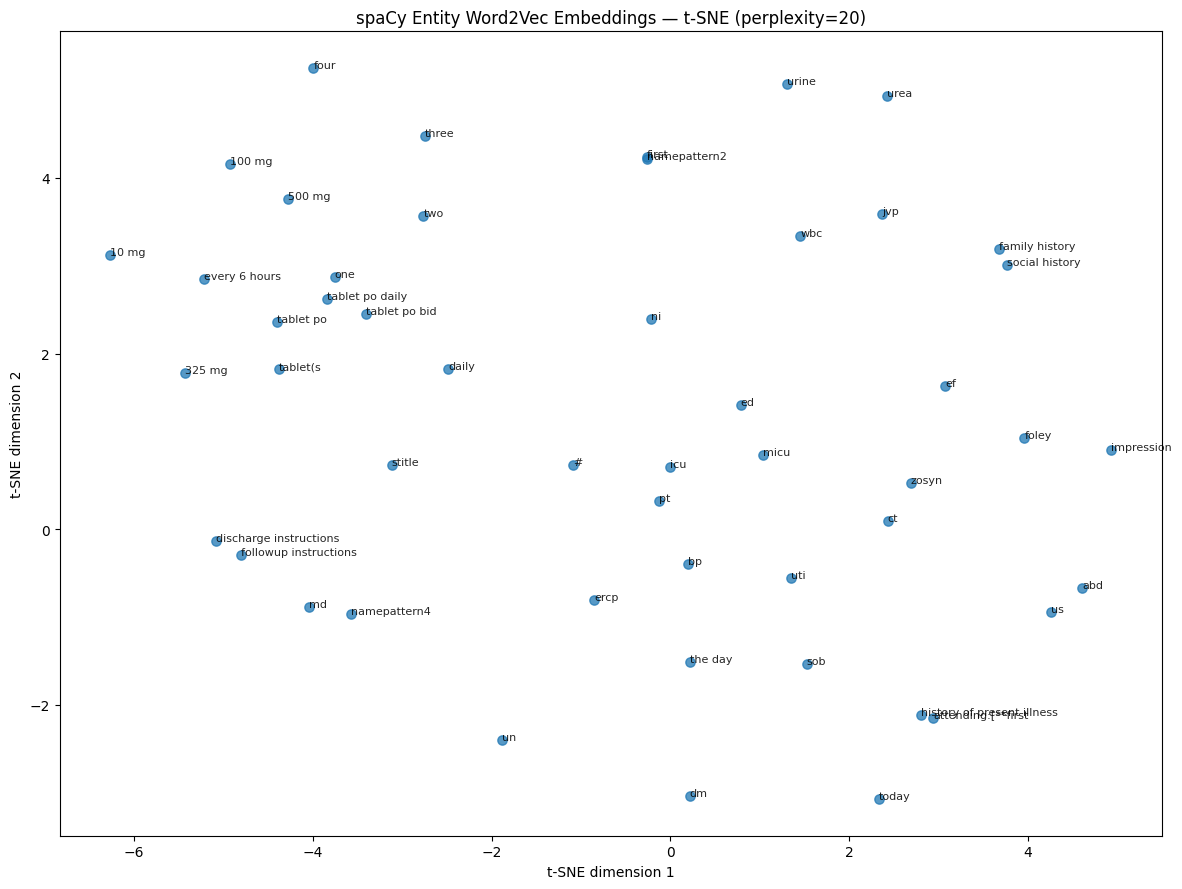

In [22]:
spacy_best_coords = \
    spacy_tsne_embeddings[
        spacy_best_perplexity
    ]

plot_tsne(
    spacy_terms,
    spacy_best_coords,
    (
        "spaCy Entity Word2Vec Embeddings — "
        f"t-SNE (perplexity="
        f"{spacy_best_perplexity})"
    )
)

# 2. SciSpaCy

SciSpaCy is designed for biomedical and scientific text. This analysis
uses `en_ner_bc5cdr_md`, which identifies biomedical entities in the
categories **DISEASE** and **CHEMICAL**. This makes it particularly
appropriate for comparing disease and medication terminology in sepsis
discharge summaries with the general-purpose spaCy model.

In [23]:
scispacy_nlp = spacy.load(
    "en_ner_bc5cdr_md"
)

print(scispacy_nlp.pipe_names)

['tok2vec', 'tagger', 'attribute_ruler', 'lemmatizer', 'parser', 'ner']


In [24]:
# Run on the sample note
scispacy_sample_doc = \
    scispacy_nlp(sample_text)

print("SciSpaCy entities from sample note:\n")

for ent in scispacy_sample_doc.ents[:50]:
    print(
        f"{ent.text:<40} "
        f"{ent.label_:<15}"
    )

SciSpaCy entities from sample note:

amputation                               DISEASE        
lower extremity bullae                   DISEASE        
purpura                                  DISEASE        
bacitracin                               CHEMICAL       
Methicillin                              CHEMICAL       
Epidermidis                              DISEASE        
Vancomycin                               CHEMICAL       
metronidazole                            CHEMICAL       
ceftazidime                              CHEMICAL       
sepsis                                   DISEASE        
Lasix                                    CHEMICAL       
anasarca                                 DISEASE        
creatine                                 CHEMICAL       
creatinine                               CHEMICAL       
distress/fatigue                         CHEMICAL       
acidosis                                 DISEASE        
ARDS                                     DISEASE   

In [25]:
displacy.render(
    scispacy_sample_doc,
    style="ent",
    jupyter=True
)

In [26]:
# Full corpus
scispacy_entities, scispacy_sequences = \
    extract_entities(
        scispacy_nlp,
        texts,
        hadm_ids,
        model_name="SciSpaCy",
        batch_size=8
    )

SciSpaCy:   0%|          | 0/500 [00:00<?, ?it/s]

In [27]:
summarize_entities(
    scispacy_entities,
    "SciSpaCy"
)


SciSpaCy
Total entity mentions: 68,265
Unique entities: 8,438
Admissions with entities: 500

Entity labels:


,LABEL,COUNT
0,DISEASE,40064
1,CHEMICAL,28201



Top 20 entities:


,ENTITY,COUNT
0,pain,1166
1,vancomycin,840
2,sepsis,774
3,pneumonia,753
4,hypotension,742
5,infection,660
6,fever,629
7,edema,579
8,heparin,542
9,hypertension,411


In [28]:
# compare the two biomedical labels (CHEMICAL and DISEASE)
display(
    scispacy_entities
    .groupby(["LABEL", "TOKEN"])
    .size()
    .reset_index(name="COUNT")
    .sort_values(
        ["LABEL", "COUNT"],
        ascending=[True, False]
    )
    .groupby("LABEL")
    .head(15)
)

,LABEL,TOKEN,COUNT
2750,CHEMICAL,vancomycin,840
1257,CHEMICAL,heparin,542
1488,CHEMICAL,lasix,393
777,CHEMICAL,creatinine,389
383,CHEMICAL,aspirin,352
2300,CHEMICAL,q6h,336
720,CHEMICAL,co2,314
1076,CHEMICAL,flagyl,310
1524,CHEMICAL,levofloxacin,275
2260,CHEMICAL,pt,274


## SciSpaCy — Word2Vec

In [29]:
scispacy_w2v = train_entity_word2vec(
    scispacy_sequences,
    "SciSpaCy"
)

SciSpaCy: 500 notes contain entities
SciSpaCy: 68,265 entity tokens available for Word2Vec
SciSpaCy Word2Vec vocabulary: 3,494 entities


In [30]:
show_similar_entities(
    scispacy_w2v,
    [
        "sepsis",
        "pneumonia",
        "vancomycin",
        "renal failure"
    ]
)


Query: sepsis
  hypotension                         0.728
  lft abnormalities                   0.629
  infectious colitis                  0.605
  colistin                            0.597
  vancomycin                          0.596

Query: pneumonia
  multilobar                          0.618
  desaturations                       0.612
  upper lobe pneumonia                0.609
  carbon monoxide poisoning           0.596
  community-acquired pneumonia        0.593

Query: vancomycin
  flagyl                              0.694
  cephalosporin                       0.690
  cytopenias                          0.690
  pen g                               0.655
  cefipime                            0.622

Query: renal failure
  terlipressin                        0.542
  atn                                 0.511
  obstructive nephropathy             0.506
  hyperkalemia                        0.492
  calcium chloride                    0.478


## SciSpaCy — tuned t-SNE

In [31]:
scispacy_terms, \
scispacy_vectors, \
scispacy_frequencies = prepare_tsne_data(
    scispacy_entities,
    scispacy_w2v,
    n_entities=50
)

scispacy_tsne_results, \
scispacy_best_perplexity, \
scispacy_tsne_embeddings = tune_tsne(
    scispacy_vectors
)

display(scispacy_tsne_results)

print(
    "Selected SciSpaCy perplexity:",
    scispacy_best_perplexity
)

,perplexity,trustworthiness,KL_divergence
0,30,0.882095,0.224706
1,15,0.878286,0.405038
2,40,0.877143,0.106802
3,20,0.874095,0.355149
4,10,0.860190,0.450727
5,5,0.850762,0.594294


Selected SciSpaCy perplexity: 30


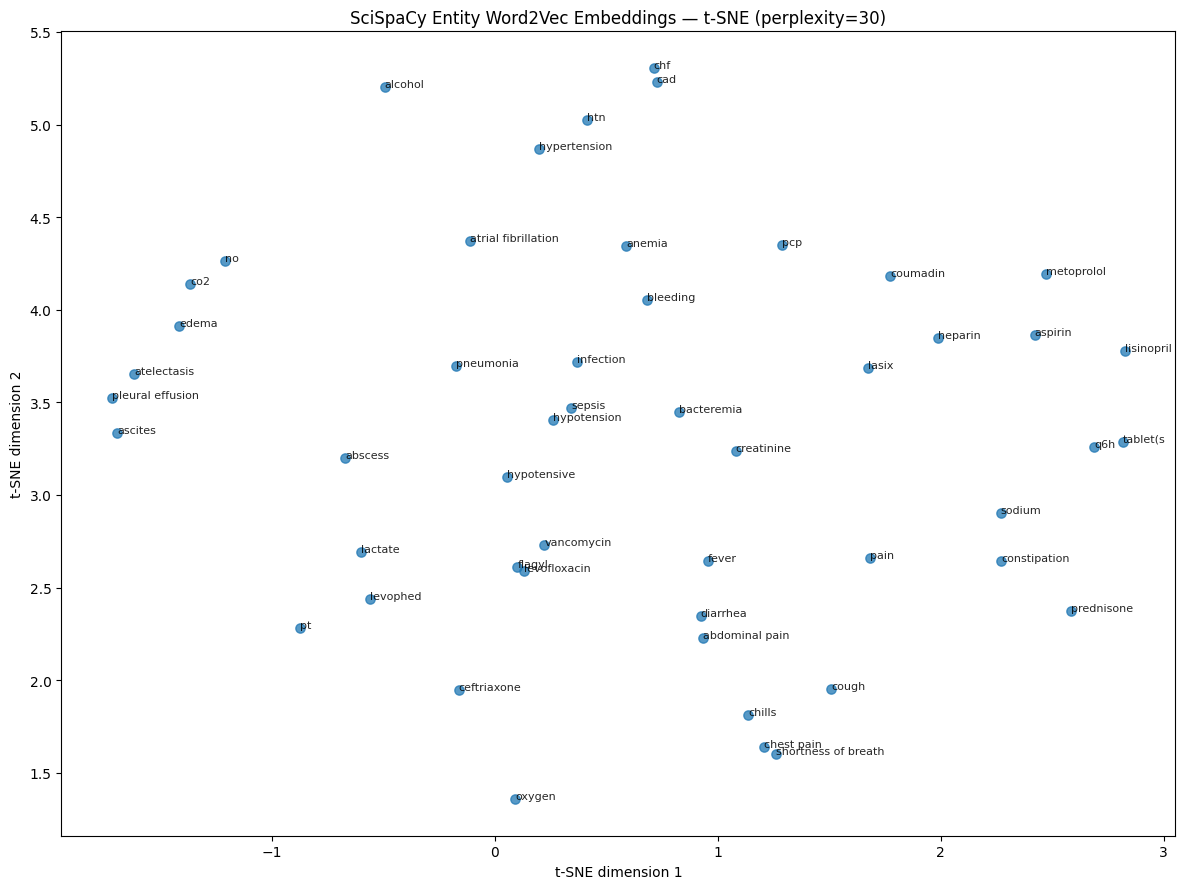

In [32]:
scispacy_best_coords = \
    scispacy_tsne_embeddings[
        scispacy_best_perplexity
    ]

plot_tsne(
    scispacy_terms,
    scispacy_best_coords,
    (
        "SciSpaCy Entity Word2Vec Embeddings — "
        f"t-SNE (perplexity="
        f"{scispacy_best_perplexity})"
    )
)

# 3. MedSpaCy

MedSpaCy is a clinical NLP framework that can add clinical context
processing to an existing spaCy pipeline.

For this analysis, MedSpaCy was loaded with the same
`en_ner_bc5cdr_md` biomedical NER model used in the SciSpaCy section. Biomedical entities are identified using the same underlying
DISEASE/CHEMICAL NER model, while MedSpaCy adds clinical context such
as negation, uncertainty, historical status, hypothetical status,
and family experiencer.

For the Word2Vec and t-SNE analysis, only contextually **affirmed**
entities are retained. This allows comparison between biomedical
concepts as mentioned in the notes and biomedical concepts that are
affirmed in the patient's clinical context.

In [33]:
# Imports
from medspacy.visualization import visualize_ent, visualize_dep

# Suppress verbose PyRuSH log messages
from loguru import logger
logger.disable("PyRuSH")

In [34]:
medspacy_nlp = medspacy.load("en_ner_bc5cdr_md")

# Remove the default spaCy parser to avoid conflict with medspacy_pyrush
if "parser" in medspacy_nlp.pipe_names:
    medspacy_nlp.remove_pipe("parser")

# We are not using a manually constructed TargetMatcher vocabulary.
# Existing SciSpaCy entities will instead be interpreted by
# MedSpaCy's clinical context component.
if "medspacy_target_matcher" in medspacy_nlp.pipe_names:
    medspacy_nlp.remove_pipe("medspacy_target_matcher")

print(medspacy_nlp.pipe_names)

['tok2vec', 'tagger', 'attribute_ruler', 'lemmatizer', 'ner', 'medspacy_pyrush', 'medspacy_context']


In [35]:
medspacy_sample_doc = \
    medspacy_nlp(sample_text)

# Visualize MedSpaCy with context labels
def get_context_labels(ent):
    """
    Return all MedSpaCy context attributes that apply
    to an extracted entity.
    """
    statuses = []

    if ent._.is_negated:
        statuses.append("NEGATED")

    if ent._.is_uncertain:
        statuses.append("UNCERTAIN")

    if ent._.is_historical:
        statuses.append("HISTORICAL")

    if ent._.is_hypothetical:
        statuses.append("HYPOTHETICAL")

    if ent._.is_family:
        statuses.append("FAMILY")

    if not statuses:
        statuses.append("AFFIRMED")

    return statuses

manual_ents = []

for ent in medspacy_sample_doc.ents:

    context = " | ".join(
        get_context_labels(ent)
    )

    manual_ents.append({
        "start": ent.start_char,
        "end": ent.end_char,
        "label": f"{ent.label_} | {context}"
    })

visualization_data = {
    "text": medspacy_sample_doc.text,
    "ents": manual_ents,
    "title": "MedSpaCy Entities with Clinical Context"
}

displacy.render(
    visualization_data,
    style="ent",
    manual=True,
    jupyter=True
)

In [36]:
# MedSpaCy sample with context detection
print(
    "MedSpaCy entities and clinical context:\n"
)

for ent in medspacy_sample_doc.ents:
    print(
        f"{ent.text:<30} "
        f"{ent.label_:<12} "
        f"context={' | '.join(get_context_labels(ent))}"
    )

MedSpaCy entities and clinical context:

amputation                     DISEASE      context=AFFIRMED
lower extremity bullae         DISEASE      context=AFFIRMED
purpura                        DISEASE      context=AFFIRMED
bacitracin                     CHEMICAL     context=AFFIRMED
Methicillin                    CHEMICAL     context=AFFIRMED
Epidermidis                    DISEASE      context=AFFIRMED
Vancomycin                     CHEMICAL     context=AFFIRMED
metronidazole                  CHEMICAL     context=AFFIRMED
ceftazidime                    CHEMICAL     context=AFFIRMED
sepsis                         DISEASE      context=UNCERTAIN
Lasix                          CHEMICAL     context=AFFIRMED
anasarca                       DISEASE      context=AFFIRMED
creatine                       CHEMICAL     context=AFFIRMED
creatinine                     CHEMICAL     context=AFFIRMED
respiratory distress           DISEASE      context=AFFIRMED
fatigue                        DISEASE     

In [37]:
# MedSpaCy has extra clinical context fields, so we use a specialized extractor
def medspacy_context_status(ent):

    if ent._.is_negated:
        return "NEGATED"

    if ent._.is_uncertain:
        return "UNCERTAIN"

    if ent._.is_historical:
        return "HISTORICAL"

    if ent._.is_hypothetical:
        return "HYPOTHETICAL"

    if ent._.is_family:
        return "FAMILY"

    return "AFFIRMED"

def extract_medspacy_entities(
    nlp,
    texts,
    hadm_ids,
    batch_size=8
):
    rows = []
    affirmed_sequences = []

    docs = nlp.pipe(
        texts,
        batch_size=batch_size
    )

    for i, doc in enumerate(
        tqdm(
            docs,
            total=len(texts),
            desc="MedSpaCy"
        )
    ):

        hadm_id = hadm_ids[i]
        affirmed_entities = []

        for ent in doc.ents:
            entity_text = re.sub(
                r"\s+",
                " ",
                ent.text.strip()
            )

            token = normalize_entity_text(
                entity_text
            )

            if token is None:
                continue

            status = medspacy_context_status(ent)

            rows.append({
                "MODEL": "MedSpaCy",
                "HADM_ID": hadm_id,
                "ENTITY": entity_text,
                "LABEL": ent.label_,
                "TOKEN": token,
                "CONTEXT": status,
                "NEGATED": ent._.is_negated,
                "UNCERTAIN": ent._.is_uncertain,
                "HISTORICAL": ent._.is_historical,
                "HYPOTHETICAL": ent._.is_hypothetical,
                "FAMILY": ent._.is_family
            })

            # Use clinically affirmed concepts for
            # MedSpaCy Word2Vec and t-SNE
            if status == "AFFIRMED":
                affirmed_entities.append(token)

        affirmed_sequences.append(
            affirmed_entities
        )

    return (
        pd.DataFrame(rows),
        affirmed_sequences
    )

In [38]:
medspacy_entities, medspacy_sequences = \
    extract_medspacy_entities(
        medspacy_nlp,
        texts,
        hadm_ids
    )

MedSpaCy:   0%|          | 0/500 [00:00<?, ?it/s]

In [39]:
summarize_entities(
    medspacy_entities,
    "MedSpaCy"
)


MedSpaCy
Total entity mentions: 71,112
Unique entities: 7,568
Admissions with entities: 500

Entity labels:


,LABEL,COUNT
0,DISEASE,40347
1,CHEMICAL,30765



Top 20 entities:


,ENTITY,COUNT
0,pain,1194
1,vancomycin,879
2,sepsis,831
3,hypotension,795
4,pneumonia,787
5,infection,674
6,fever,664
7,glucose,631
8,edema,601
9,heparin,553


In [40]:
print("MedSpaCy contextual status:")
context_counts = (
    medspacy_entities["CONTEXT"]
    .value_counts()
    .rename_axis("CONTEXT")
    .reset_index(name="COUNT")
)

context_counts["PERCENT"] = (
    context_counts["COUNT"]
    / context_counts["COUNT"].sum()
    * 100
)

context_counts

MedSpaCy contextual status:


,CONTEXT,COUNT,PERCENT
0,AFFIRMED,56905,80.021656
1,NEGATED,7703,10.832208
2,HISTORICAL,2624,3.689954
3,UNCERTAIN,1878,2.640904
4,HYPOTHETICAL,1457,2.048881
5,FAMILY,545,0.766397


In [41]:
print("Examples of negated clinical concepts:")

display(
    medspacy_entities.loc[
        medspacy_entities["NEGATED"],
        [
            "HADM_ID",
            "ENTITY",
            "LABEL",
            "CONTEXT"
        ]
    ].head(25)
)

Examples of negated clinical concepts:


,HADM_ID,ENTITY,LABEL,CONTEXT
26,100262,hemorrhage,DISEASE,NEGATED
27,100262,hydrocephalus,DISEASE,NEGATED
30,100262,hydrocephalus,DISEASE,NEGATED
31,100262,infarcts,DISEASE,NEGATED
32,100262,abscess,DISEASE,NEGATED
33,100262,hematoma,DISEASE,NEGATED
41,100262,lymphadenopathy,DISEASE,NEGATED
42,100262,retroperitoneal hematoma,DISEASE,NEGATED
44,100262,lymphadenopathy,DISEASE,NEGATED
45,100262,atrial septal defect,DISEASE,NEGATED


## MedSpaCy — Word2Vec

In [42]:
medspacy_w2v = train_entity_word2vec(
    medspacy_sequences,
    "MedSpaCy affirmed entities",
    min_count=2
)

MedSpaCy affirmed entities: 500 notes contain entities
MedSpaCy affirmed entities: 56,905 entity tokens available for Word2Vec
MedSpaCy affirmed entities Word2Vec vocabulary: 2,893 entities


In [43]:
show_similar_entities(
    medspacy_w2v,
    [
        "sepsis",
        "septic shock",
        "pneumonia",
        "vancomycin",
        "acute kidney injury"
    ]
)


Query: sepsis
  vancomycin                          0.678
  hypotension                         0.641
  pneumonia                           0.600
  lft abnormalities                   0.597
  infectious colitis                  0.579

Query: septic shock
  occipital strokes                   0.502
  organ failure                       0.491
  cystitis                            0.481
  cardiovascular and respiratory failure 0.478
  mods                                0.476

Query: pneumonia
  multilobar                          0.600
  sepsis                              0.600
  upper lobe pneumonia                0.591
  vancomycin                          0.581
  aureus toxic shock syndrome         0.559

Query: vancomycin
  cytopenias                          0.685
  sepsis                              0.678
  cephalosporin                       0.654
  pcn allergy                         0.640
  cefipime                            0.624

Query: acute kidney injury
  acute liver in

## MedSpaCy — tuned t-SNE

In [44]:
medspacy_affirmed = medspacy_entities[
    medspacy_entities["CONTEXT"] == "AFFIRMED"
].copy()

medspacy_terms, \
medspacy_vectors, \
medspacy_frequencies = prepare_tsne_data(
    medspacy_affirmed,
    medspacy_w2v,
    n_entities=50
)
medspacy_tsne_results, \
medspacy_best_perplexity, \
medspacy_tsne_embeddings = tune_tsne(
    medspacy_vectors
)

display(medspacy_tsne_results)

print(
    "Selected MedSpaCy perplexity:",
    medspacy_best_perplexity
)

,perplexity,trustworthiness,KL_divergence
0,30,0.897048,0.210988
1,20,0.885333,0.338124
2,40,0.860476,0.104248
3,10,0.857429,0.550711
4,15,0.854381,0.411617
5,5,0.827429,0.647069


Selected MedSpaCy perplexity: 30


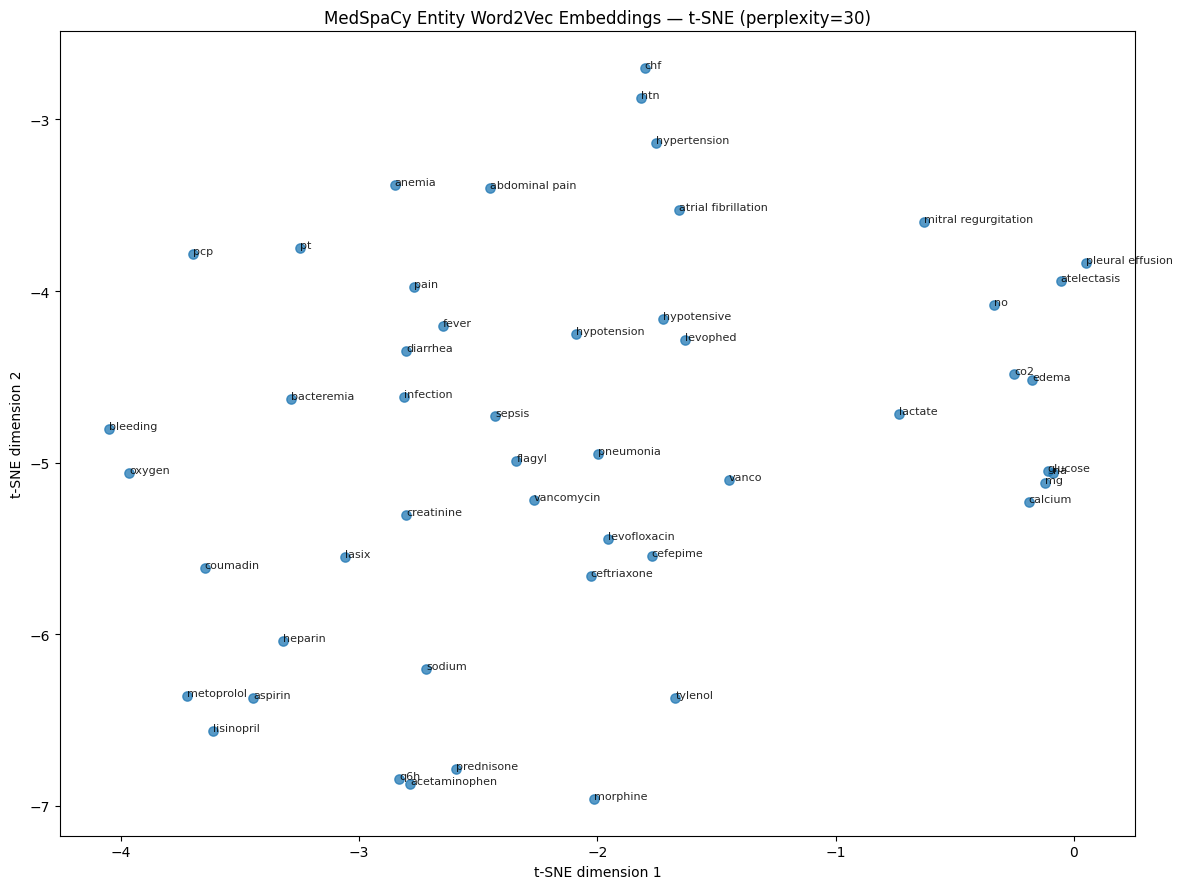

In [45]:
medspacy_best_coords = \
    medspacy_tsne_embeddings[
        medspacy_best_perplexity
    ]

plot_tsne(
    medspacy_terms,
    medspacy_best_coords,
    (
        "MedSpaCy Entity Word2Vec Embeddings — "
        f"t-SNE (perplexity="
        f"{medspacy_best_perplexity})"
    )
)

# Quantitative comparisons between models

In [46]:
def model_summary(
    model_name,
    entity_df,
    word2vec_model
):
    return {
        "Model": model_name,
        "Entity mentions": len(entity_df),
        "Unique entities":
            entity_df["TOKEN"].nunique(),
        "Admissions with entities":
            entity_df["HADM_ID"].nunique(),
        "Mean entities/admission":
            len(entity_df) /
            entity_df["HADM_ID"].nunique(),
        "Word2Vec vocabulary":
            len(word2vec_model.wv)
    }


comparison = pd.DataFrame([
    model_summary(
        "spaCy",
        spacy_entities,
        spacy_w2v
    ),
    model_summary(
        "SciSpaCy",
        scispacy_entities,
        scispacy_w2v
    ),
    model_summary(
        "MedSpaCy",
        medspacy_entities,
        medspacy_w2v
    )
])

comparison

,Model,Entity mentions,Unique entities,Admissions with entities,Mean entities/admission,Word2Vec vocabulary
0,spaCy,65953,15769,500,131.906,4982
1,SciSpaCy,68265,8438,500,136.530,3494
2,MedSpaCy,71112,7568,500,142.224,2893


In [47]:
# t-SNE tuning results
tsne_comparison = pd.DataFrame([
    {
        "Model": "spaCy",
        "Best perplexity":
            spacy_best_perplexity,
        "Trustworthiness":
            spacy_tsne_results.iloc[0]
            ["trustworthiness"]
    },
    {
        "Model": "SciSpaCy",
        "Best perplexity":
            scispacy_best_perplexity,
        "Trustworthiness":
            scispacy_tsne_results.iloc[0]
            ["trustworthiness"]
    },
    {
        "Model": "MedSpaCy",
        "Best perplexity":
            medspacy_best_perplexity,
        "Trustworthiness":
            medspacy_tsne_results.iloc[0]
            ["trustworthiness"]
    }
])

tsne_comparison

,Model,Best perplexity,Trustworthiness
0,spaCy,20,0.892286
1,SciSpaCy,30,0.882095
2,MedSpaCy,30,0.897048


In [48]:
# Compare entity overlap
spacy_set = set(
    spacy_entities["TOKEN"]
)

scispacy_set = set(
    scispacy_entities["TOKEN"]
)

medspacy_set = set(
    medspacy_entities["TOKEN"]
)


def jaccard(a, b):
    return len(a & b) / len(a | b)


overlap = pd.DataFrame({
    "Comparison": [
        "spaCy vs SciSpaCy",
        "spaCy vs MedSpaCy",
        "SciSpaCy vs MedSpaCy"
    ],
    "Shared entities": [
        len(spacy_set & scispacy_set),
        len(spacy_set & medspacy_set),
        len(scispacy_set & medspacy_set)
    ],
    "Jaccard similarity": [
        jaccard(spacy_set, scispacy_set),
        jaccard(spacy_set, medspacy_set),
        jaccard(scispacy_set, medspacy_set)
    ]
})

overlap

,Comparison,Shared entities,Jaccard similarity
0,spaCy vs SciSpaCy,1318,0.057582
1,spaCy vs MedSpaCy,1220,0.055161
2,SciSpaCy vs MedSpaCy,6876,0.753122


In [49]:
# Show the top entities side-by-side
def top_entities_table(
    entity_df,
    model_name,
    n=15
):
    result = (
        entity_df["TOKEN"]
        .value_counts()
        .head(n)
        .reset_index()
    )

    result.columns = [
        "Entity",
        model_name
    ]

    return result


top_spacy = top_entities_table(
    spacy_entities,
    "spaCy count"
)

top_scispacy = top_entities_table(
    scispacy_entities,
    "SciSpaCy count"
)

top_medspacy = top_entities_table(
    medspacy_entities,
    "MedSpaCy count"
)

print("spaCy")
display(top_spacy)

print("SciSpaCy")
display(top_scispacy)

print("MedSpaCy")
display(top_medspacy)

spaCy


,Entity,spaCy count
0,one,2912
1,daily,1100
2,pt,982
3,stitle,859
4,two,656
5,ni,637
6,tablet_po_daily,513
7,first,430
8,namepattern4,421
9,ct,414


SciSpaCy


,Entity,SciSpaCy count
0,pain,1166
1,vancomycin,840
2,sepsis,774
3,pneumonia,753
4,hypotension,742
5,infection,660
6,fever,629
7,edema,579
8,heparin,542
9,hypertension,411


MedSpaCy


,Entity,MedSpaCy count
0,pain,1194
1,vancomycin,879
2,sepsis,831
3,hypotension,795
4,pneumonia,787
5,infection,674
6,fever,664
7,glucose,631
8,edema,601
9,heparin,553


# Comparison and Interpretation

## spaCy

spaCy provided a useful general-purpose English NLP baseline, but its
entity categories were not well aligned with clinical discharge
summaries.

It extracted **65,953 entity mentions** representing **15,769 unique
entity strings** across all 500 admissions. However, many of its most
frequent entities were generic, numerical, administrative, or
de-identification-related terms such as `one`, `daily`, `pt`,
`stitle`, and `namepattern4`. Its most common entity labels were
general English categories such as ORG, CARDINAL, PERSON, and DATE
rather than medical concepts.

This limitation was also visible in the Word2Vec results. For example,
the nearest neighbors of `sepsis` included phrases such as
`the last few days`, `w/ h/o`, and `one day later`. Important clinical
concepts such as `pneumonia` and `renal failure` were not present in
the spaCy entity Word2Vec vocabulary.

These results show that a general-purpose NER model can process
clinical text syntactically but may not identify the concepts most
relevant to clinical interpretation.

---

## SciSpaCy

SciSpaCy was substantially better aligned with the medical content of
the corpus.

Using `en_ner_bc5cdr_md`, SciSpaCy extracted **68,265 biomedical entity
mentions** representing **8,438 unique entities**. Of these,
**40,064 were DISEASE entities** and **28,201 were CHEMICAL entities**.

The most frequently extracted concepts were much more clinically
meaningful for a sepsis cohort. Examples included:

- `pain`
- `vancomycin`
- `sepsis`
- `pneumonia`
- `hypotension`
- `infection`
- `fever`
- `heparin`

The Word2Vec results also produced more interpretable clinical
relationships. Examples included:

- `sepsis` → `hypotension`
- `pneumonia` → `upper lobe pneumonia` and
  `community-acquired pneumonia`
- `vancomycin` → `Flagyl`, `cephalosporin`, and `cefipime`
- `renal failure` → `ATN` and `hyperkalemia`

SciSpaCy was not error-free. Terms such as `creatinine`, `q6h`, `pt`,
and `no` were sometimes classified as CHEMICAL. Therefore,
domain-specific biomedical NER substantially improves clinical
relevance but does not eliminate extraction or classification errors.

---

## MedSpaCy

The MedSpaCy analysis was designed differently from the first two
analyses. Rather than defining a manually selected vocabulary,
MedSpaCy was loaded with the same `en_ner_bc5cdr_md` biomedical NER
model used by SciSpaCy. MedSpaCy then added clinical context processing
to the extracted biomedical entities.

The resulting pipeline identified **71,112 entity mentions** and
**7,568 unique entity strings** across all 500 admissions:
**40,347 DISEASE mentions** and **30,765 CHEMICAL mentions**.

Because SciSpaCy and MedSpaCy share the same underlying biomedical NER
model in this experiment, their entity extraction results are expected
to be much more similar to each other than either is to general-purpose
spaCy. Their unique-entity sets had a **Jaccard similarity of 0.753**,
compared with approximately **0.06** between spaCy and either
biomedical pipeline.

The principal contribution of MedSpaCy was not broader entity
recognition, but **clinical contextualization**. Of the 71,112
biomedical mentions:

- **56,905 (80.0%)** were AFFIRMED
- **7,703 (10.8%)** were NEGATED
- **2,624 (3.7%)** were HISTORICAL
- **1,878 (2.6%)** were UNCERTAIN
- **1,457 (2.0%)** were HYPOTHETICAL
- **545 (0.8%)** referred to FAMILY context

This is clinically important because the presence of a medical term
in a note does not necessarily mean that the patient currently has
that condition. For example, a note may state that there is
"no evidence of pneumonia," describe a historical disease, or discuss
a condition as a possibility rather than a confirmed diagnosis.
MedSpaCy preserves distinctions that entity extraction alone cannot.

For the MedSpaCy Word2Vec analysis, only **affirmed entities** were
used. This reduced the corpus from 71,112 extracted mentions to
**56,905 affirmed entity tokens**, producing a Word2Vec vocabulary of
**2,893 concepts**.

The resulting relationships remained clinically interpretable.
For example:

- `sepsis` was associated with `vancomycin`, `hypotension`, and
  `pneumonia`
- `pneumonia` was associated with `sepsis`,
  `upper lobe pneumonia`, and `vancomycin`
- `vancomycin` was associated with other antimicrobial concepts such
  as `cephalosporin` and `cefipime`
- `septic shock` was associated with concepts including
  `organ failure` and cardiovascular/respiratory failure

Thus, the MedSpaCy embedding represents a somewhat different semantic
space from the SciSpaCy embedding: it is based only on biomedical
entities that were contextually affirmed.

---

## Word2Vec Comparison

The Word2Vec models were trained using sequences of entities extracted
from each discharge summary.

The resulting vocabulary sizes were:

- **spaCy: 4,982**
- **SciSpaCy: 3,494**
- **MedSpaCy affirmed entities: 2,893**

The larger spaCy vocabulary should not be interpreted as superior
clinical coverage. Much of that vocabulary consisted of general
English, administrative, numerical, and de-identification-related
entities.

SciSpaCy produced a smaller but substantially more medically focused
vocabulary. MedSpaCy produced the smallest vocabulary because entities
classified as negated, historical, uncertain, hypothetical, or family
context were excluded before Word2Vec training.

Therefore, the decreasing vocabulary size reflects progressively more
domain-specific and context-specific filtering rather than decreasing
NLP capability.

---

## t-SNE

t-SNE was applied to Word2Vec vectors for the 50 most frequent
eligible entities from each approach. Multiple perplexity values were
tested rather than relying on a single arbitrary setting.

The best configurations were:

| NLP approach | Selected perplexity | Trustworthiness |
|---|---:|---:|
| spaCy | 20 | 0.892 |
| SciSpaCy | 30 | 0.882 |
| MedSpaCy affirmed entities | 30 | 0.897 |

These trustworthiness scores measure how well local neighborhoods in
the original Word2Vec space were preserved in two dimensions. They
should **not** be interpreted as measures of NLP extraction accuracy
or as evidence that one NLP library is globally superior to another.

Likewise, t-SNE is most useful for inspecting local clustering and
neighborhood relationships. Absolute distances and apparent global
separation between clusters should be interpreted cautiously.

---

## Overall Interpretation

The three analyses illustrate progressively more specialized ways of
processing clinical text rather than three interchangeable competing
NER systems.

**spaCy** provided the general-purpose baseline. It extracted many
entities, but a substantial portion were not clinically meaningful,
and its learned entity relationships were less useful for analyzing
sepsis discharge summaries.

**SciSpaCy** added biomedical specialization. Its DISEASE and CHEMICAL
entities were substantially more relevant to the clinical corpus, and
its Word2Vec embeddings showed recognizable relationships among
diseases, complications, and medications.

**MedSpaCy** added a different layer of clinical understanding. In
this experiment it reused the biomedical entity recognizer rather than
attempting to replace it, and then determined whether those concepts
were affirmed, negated, historical, uncertain, hypothetical, or
associated with family context. Approximately **20% of all biomedical
entity mentions were not simply affirmed**, demonstrating why
extracting an entity alone is not sufficient for interpreting a
clinical note.

The results therefore suggest a natural progression:

**general-purpose NLP → biomedical entity recognition → clinical
context interpretation**

For EHR text analysis, the most informative workflow is not
necessarily to select one library over the others, but to combine
domain-specific biomedical entity recognition with clinical context
processing. In this sepsis cohort, SciSpaCy improved identification of
medically meaningful concepts, while MedSpaCy added information needed
to interpret what those concepts actually represented in the patient's
clinical record.

# Bonus: BioClinicalBERT Contextual Embeddings

For bonus credit, BioClinicalBERT was applied to the same 500
MIMIC-III sepsis discharge summaries.

BioClinicalBERT is a transformer language model initialized from
BioBERT and further pretrained on clinical notes from MIMIC-III.
Unlike Word2Vec, which learns one static vector for each entity,
BERT produces contextual token representations whose values depend
on the surrounding clinical text.

For this experiment:

1. Each discharge summary was tokenized with BioClinicalBERT.
2. The first 512 tokens of each note were processed.
3. Token embeddings from the first 512 tokens were mean-pooled to create
   one 768-dimensional contextual representation for each note segment.
4. PCA reduced these embeddings to 50 dimensions.
5. Tuned t-SNE projected the resulting representations into two
   dimensions for exploratory visualization.

The purpose of this analysis is to demonstrate transformer-based
clinical text representation, not to evaluate BioClinicalBERT as a
diagnostic classifier.

In [50]:
%pip install -q \
    "numpy==1.26.4" \
    "transformers>=4.44,<5"

In [51]:
# Load BioClinicalBERT
import torch
from transformers import AutoTokenizer, AutoModel

BIOCLINICALBERT = "emilyalsentzer/Bio_ClinicalBERT"

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

clinical_tokenizer = AutoTokenizer.from_pretrained(
    BIOCLINICALBERT
)

clinical_bert = AutoModel.from_pretrained(
    BIOCLINICALBERT
)

clinical_bert = clinical_bert.to(device)
clinical_bert.eval()

print("Model loaded:", BIOCLINICALBERT)
print("Hidden size:", clinical_bert.config.hidden_size)

Device: cpu


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/436M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/436M [00:00<?, ?B/s]

Model loaded: emilyalsentzer/Bio_ClinicalBERT
Hidden size: 768


## Generate one contextual embedding per MIMIC note

In [52]:
# Define mean pooling
def mean_pooling(last_hidden_state, attention_mask):
    """
    Average token embeddings while ignoring padding tokens.
    """

    mask = attention_mask.unsqueeze(-1).float()

    summed = (
        last_hidden_state * mask
    ).sum(dim=1)

    counts = mask.sum(dim=1).clamp(min=1e-9)

    return summed / counts

# Process all 500 discharge summaries in batches
def create_bioclinicalbert_embeddings(
    texts,
    tokenizer,
    model,
    device,
    batch_size=8,
    max_length=512
):
    """
    Create one BioClinicalBERT embedding per clinical note.
    """

    embeddings = []

    for start in tqdm(
        range(0, len(texts), batch_size),
        desc="BioClinicalBERT"
    ):

        batch_texts = texts[
            start:start + batch_size
        ]

        encoded = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt"
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        with torch.no_grad():

            output = model(**encoded)

            pooled = mean_pooling(
                output.last_hidden_state,
                encoded["attention_mask"]
            )

        embeddings.append(
            pooled.cpu().numpy()
        )

    return np.vstack(embeddings)

In [53]:
bert_texts = notes["TEXT"].tolist()

bert_embeddings = \
    create_bioclinicalbert_embeddings(
        bert_texts,
        clinical_tokenizer,
        clinical_bert,
        device,
        batch_size=8,
        max_length=512
    )

print(
    "BioClinicalBERT embedding shape:",
    bert_embeddings.shape
)

BioClinicalBERT:   0%|          | 0/63 [00:00<?, ?it/s]

BioClinicalBERT embedding shape: (500, 768)


## Reduce 768 dimensions to 50 with PCA

In [54]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize

bert_embeddings_norm = normalize(
    bert_embeddings
)

pca = PCA(
    n_components=50,
    random_state=42
)

bert_pca = pca.fit_transform(
    bert_embeddings_norm
)

print(
    "PCA output shape:",
    bert_pca.shape
)

print(
    "Variance explained by 50 PCs:",
    f"{pca.explained_variance_ratio_.sum():.3f}"
)

PCA output shape: (500, 50)
Variance explained by 50 PCs: 0.864


## Tune t-SNE as we did for the required models

In [55]:
bert_tsne_results, \
bert_best_perplexity, \
bert_tsne_embeddings = tune_tsne(
    bert_pca,
    perplexities=(
        5,
        10,
        20,
        30,
        40,
        50
    )
)

display(bert_tsne_results)

print(
    "Selected BioClinicalBERT perplexity:",
    bert_best_perplexity
)

,perplexity,trustworthiness,KL_divergence
0,20,0.956750,1.210933
1,10,0.952459,1.317626
2,30,0.952376,1.131714
3,50,0.951553,0.944325
4,40,0.947293,1.110399
5,5,0.946008,1.278305


Selected BioClinicalBERT perplexity: 20


In [56]:
def assign_sepsis_group(code_string):

    codes = set(
        str(code_string).split(",")
    )

    # Highest-severity category first
    if "78552" in codes:
        return "Septic shock"

    if "99592" in codes:
        return "Severe sepsis"

    return "Sepsis / septicemia"


notes["SEPSIS_GROUP"] = (
    notes["SEPSIS_ICD9_CODES"]
    .apply(assign_sepsis_group)
)

display(
    notes["SEPSIS_GROUP"]
    .value_counts()
    .rename_axis("GROUP")
    .reset_index(name="NOTES")
)

,GROUP,NOTES
0,Septic shock,223
1,Sepsis / septicemia,173
2,Severe sepsis,104


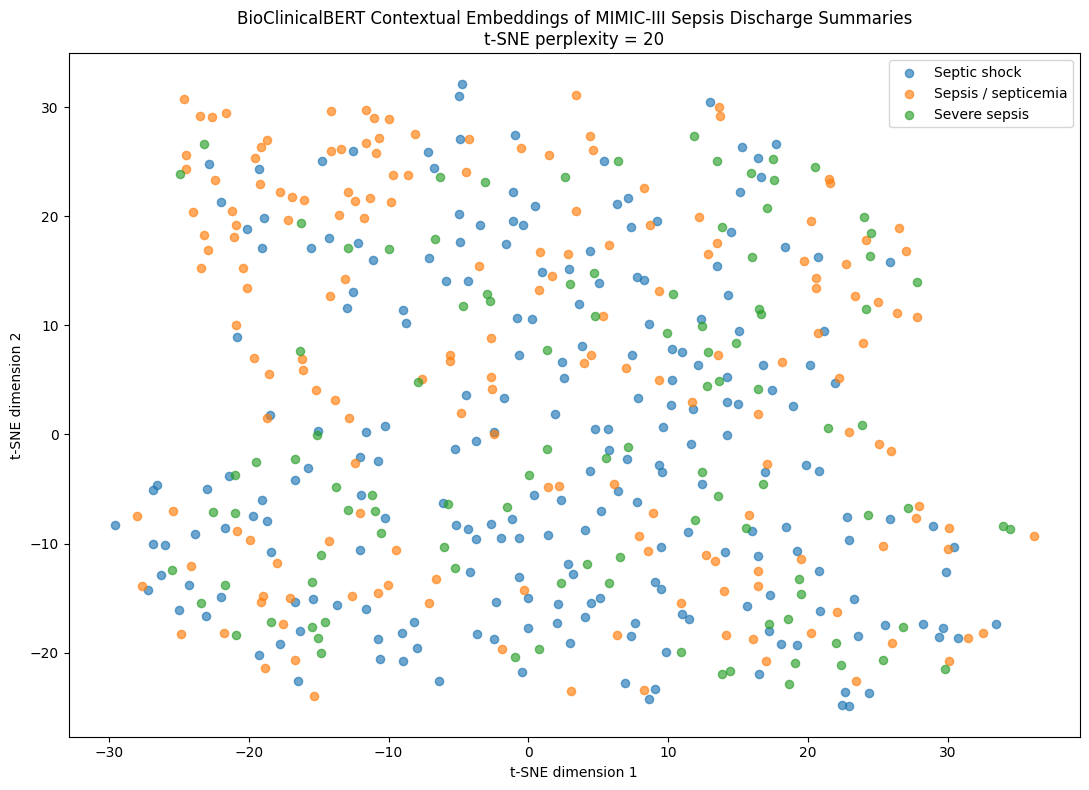

In [57]:
bert_coords = bert_tsne_embeddings[
    bert_best_perplexity
]

plt.figure(figsize=(11, 8))

for group in notes["SEPSIS_GROUP"].unique():

    mask = (
        notes["SEPSIS_GROUP"] == group
    ).to_numpy()

    plt.scatter(
        bert_coords[mask, 0],
        bert_coords[mask, 1],
        s=35,
        alpha=0.65,
        label=group
    )

plt.title(
    "BioClinicalBERT Contextual Embeddings of "
    "MIMIC-III Sepsis Discharge Summaries\n"
    f"t-SNE perplexity = "
    f"{bert_best_perplexity}"
)

plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.legend()

plt.tight_layout()
plt.show()

In [58]:
from sklearn.metrics.pairwise import cosine_similarity

bert_similarity = cosine_similarity(
    bert_embeddings_norm
)

# Remove self-similarity
np.fill_diagonal(
    bert_similarity,
    -1
)

for i in range(5):

    nearest = np.argmax(
        bert_similarity[i]
    )

    print(
        f"\nNote {i} "
        f"(HADM_ID={notes.iloc[i]['HADM_ID']})"
    )

    print(
        "Group:",
        notes.iloc[i]["SEPSIS_GROUP"]
    )

    print(
        "Most similar note:",
        nearest,
        f"(HADM_ID="
        f"{notes.iloc[nearest]['HADM_ID']})"
    )

    print(
        "Similar note group:",
        notes.iloc[nearest]["SEPSIS_GROUP"]
    )

    print(
        "Cosine similarity:",
        f"{bert_similarity[i, nearest]:.3f}"
    )


Note 0 (HADM_ID=100262)
Group: Septic shock
Most similar note: 49 (HADM_ID=109386)
Similar note group: Sepsis / septicemia
Cosine similarity: 0.989

Note 1 (HADM_ID=100454)
Group: Sepsis / septicemia
Most similar note: 143 (HADM_ID=127115)
Similar note group: Severe sepsis
Cosine similarity: 0.990

Note 2 (HADM_ID=100539)
Group: Sepsis / septicemia
Most similar note: 401 (HADM_ID=180378)
Similar note group: Sepsis / septicemia
Cosine similarity: 0.987

Note 3 (HADM_ID=100598)
Group: Sepsis / septicemia
Most similar note: 226 (HADM_ID=143281)
Similar note group: Septic shock
Cosine similarity: 0.991

Note 4 (HADM_ID=100995)
Group: Severe sepsis
Most similar note: 188 (HADM_ID=136177)
Similar note group: Sepsis / septicemia
Cosine similarity: 0.992


In [59]:
query_index = 0

neighbor_index = np.argmax(
    bert_similarity[query_index]
)

print("QUERY NOTE")
print("-" * 60)
print(
    notes.iloc[query_index]["TEXT"][:1000]
)

print("\n\nMOST SIMILAR NOTE")
print("-" * 60)
print(
    notes.iloc[neighbor_index]["TEXT"][:1000]
)

QUERY NOTE
------------------------------------------------------------
Admission Date:  [**2142-4-28**]              Discharge Date:   [**2142-6-11**]

Date of Birth:  [**2120-10-16**]             Sex:   M

Service: MEDICINE

Allergies:
Sulfa (Sulfonamides) / Shellfish

Attending:[**First Name3 (LF) 30**]
Chief Complaint:
Purpura, fever, "flu-like" symptoms

Major Surgical or Invasive Procedure:
Oral Intubation
Central Line Placement
[**2142-5-14**]: Placement of 8.0 Portex tracheostomy tube, placement of
#19 French Ponsky percutaneous endoscopic gastrostomy tube,
flexible
bronchoscopy.
[**2142-5-23**]: PICC Line Placement
[**2142-5-28**]: Right foot incision and drainage.
[**2142-5-30**]: Bilateral incision and drainage with debridement of both
feet.


History of Present Illness:
The patient is a 21 year old African-American male with no
significant past medical history who presented to the ED on
[**2142-4-28**] after being transferred from [**Hospital 1474**] Hospital. The
patient h

# Bonus Interpretation: BioClinicalBERT

BioClinicalBERT was successfully applied to all **500 MIMIC-III sepsis
discharge summaries**.

For each note, only the **first 512 tokens** were processed. The token
representations from this initial clinical text segment were mean-pooled
to produce one **768-dimensional contextual embedding** per note. This
differs from the Word2Vec analyses used in the required spaCy,
SciSpaCy, and MedSpaCy sections, where embeddings represented
individual extracted entities rather than note-level clinical context.

## Dimensionality Reduction

The 768-dimensional BioClinicalBERT embeddings were first reduced to
50 dimensions using PCA. The first 50 principal components retained
approximately **86.4% of the variance** in the normalized embedding
space.

t-SNE was then evaluated using perplexities of 5, 10, 20, 30, 40,
and 50. The best result was obtained at **perplexity 20**, with a
trustworthiness score of approximately **0.957**. The remaining
perplexities produced very similar trustworthiness values, especially
30, 40, and 50, suggesting that the local structure of the embedding
space was reasonably stable across several parameter settings.

The final t-SNE visualization therefore used a perplexity of **20**.

## Sepsis Severity Visualization

The t-SNE plot was colored using ICD-9-derived sepsis groups from the
original cohort:

- **223** septic shock notes
- **173** sepsis/septicemia notes
- **104** severe sepsis notes

The three groups showed substantial overlap rather than forming clearly
separated clusters. This is not unexpected because BioClinicalBERT was
not fine-tuned to classify sepsis severity. Instead, the embeddings
represent broader similarities in the language and clinical context of
the first 512 tokens of each discharge summary.

The nearest-neighbor analysis supports this interpretation. The first
five example notes had very high cosine similarities to their nearest
neighbors, approximately **0.987-0.992**, but the most similar note did
not always belong to the same ICD-9-derived severity group. For example,
some sepsis/septicemia notes were most similar to severe-sepsis or
septic-shock notes.

This suggests that similarity in clinical documentation is influenced
by shared clinical language and context and is not determined solely by
the assigned sepsis severity category.

## Comparison with Word2Vec

The Word2Vec analyses represented relationships among individual
entities such as diseases, medications, and other extracted clinical
concepts. BioClinicalBERT instead produced contextual representations
of the **initial 512-token segment of each discharge summary**.

The two approaches therefore capture different information:

- **Word2Vec** is useful for examining relationships among individual
  extracted concepts.
- **BioClinicalBERT** incorporates surrounding language and provides a
  broader representation of clinical text context.

These approaches are complementary rather than directly interchangeable.

## Limitations

This bonus analysis has several important limitations.

First, only the **first 512 tokens** of each discharge summary were
processed. Because MIMIC discharge summaries are substantially longer,
the resulting embeddings represent the beginning of each note rather
than the complete hospitalization narrative.

Second, mean pooling compresses all contextual token representations
into a single vector and therefore removes some of the detailed
token-level structure produced by the transformer.

Third, the t-SNE visualization is exploratory. Neither visual
clustering nor cosine similarity should be interpreted as diagnostic
or classification performance.

Finally, BioClinicalBERT was itself pretrained on **MIMIC-III clinical
notes**. Therefore, this analysis demonstrates the application of a
domain-specific pretrained transformer to MIMIC-III rather than an
independent evaluation of performance on previously unseen clinical
data.

## Conclusion

BioClinicalBERT provided a transformer-based complement to the
entity-level Word2Vec analyses. All 500 discharge summaries were
successfully represented as 768-dimensional contextual embeddings based
on their first 512 tokens. After PCA reduction, tuned t-SNE achieved a
best trustworthiness of approximately **0.957** at perplexity **20**.

The results demonstrate how a clinical transformer can represent
broader contextual similarity between notes, while also showing that
unsupervised embedding similarity does not simply reproduce ICD-9
sepsis severity categories.